# TUTORIAL: Data assimilation with a bimodal posterior: the Gaussian-mixture ensemble filter

* [The problem: data that do not determine the state](#problem)
* [The Gaussian-mixture ensemble filter](#filter)
* [A Bayesian view of the filter](#bayes)
* [1) Bayes' rule in two dimensions](#bayes2d)
* [2) The mirror symmetry of the Lorenz-63 equations](#symmetry)
* [3) The posterior is bimodal](#posterior)
* [4) One analysis of a bimodal forecast](#analysis)
* [5) Twin experiment](#twin)
* [Summary](#summary)

## The problem: data that do not determine the state <a class="anchor" id="problem"></a>

The Lorenz-63 equations,

$$\dot{x} = \sigma (y - x), \qquad \dot{y} = x(\rho - z) - y, \qquad \dot{z} = xy - \beta z,$$

are invariant under the mirror symmetry $\mathcal{S}: (x, y, z) \mapsto (-x, -y, z)$. If $\boldsymbol{\phi}(t) = (x, y, z)$ is a solution, so is $\mathcal{S}\boldsymbol{\phi}(t)$, and the two solutions have the same $z(t)$. Therefore, observations of $z$ alone do not distinguish the true state, $\boldsymbol{\phi}^\dagger$, from its mirror image, $\mathcal{S}\boldsymbol{\phi}^\dagger$, and the posterior of the unobserved components, $p(x, y \mid z)$, has two modes of equal probability.

An ensemble Kalman filter approximates the forecast by one Gaussian, with the mean and the covariance of the ensemble. When the members lie near both modes, the mean lies between the modes, and the covariance adds the distance between the modes to the spread within each mode. The analysis then corrects the members with correlations that belong to neither mode.

In this tutorial, we (i) introduce the Gaussian-mixture ensemble filter, which performs one analysis per mode, and derive it from Bayes' rule, with an example in two dimensions; (ii) show that $p(x, y \mid z)$ is bimodal; and (iii) compare the mixture filter with the Gaussian filter in one analysis and in a twin experiment.

## The Gaussian-mixture ensemble filter <a class="anchor" id="filter"></a>

The filter approximates the forecast probability density by a sum of $K$ Gaussians

$$p(\boldsymbol{\phi}) \approx \sum_{k=1}^{K} w_k\, \mathcal{N}\big(\boldsymbol{\phi};\ \bar{\boldsymbol{\phi}}_k,\ \boldsymbol{\mathsf{C}}_k\big),$$

where each Gaussian, $k$, is a group of members with mean $\bar{\boldsymbol{\phi}}_k$, covariance $\boldsymbol{\mathsf{C}}_k$ and weight $w_k$. With a linear measurement operator, $\boldsymbol{\mathsf{M}}$, the posterior of a Gaussian mixture is a Gaussian mixture, whose Gaussians are the Kalman analyses of the forecast Gaussians (Alspach & Sorenson, 1972). With the keyword `mixture=K` of `EnsembleFilter`, `EnSRKF` and `EnKF`, each analysis

1. fits up to $K$ Gaussians to the forecast members by expectation maximization, and selects their number with the Bayesian information criterion (Smith, 2007; Sondergaard & Lermusiaux, 2013);
2. updates the members of each Gaussian with the analysis of the filter, from the mean and the covariance of that Gaussian;
3. updates the weight of each Gaussian with the probability of the data under its forecast (the equation below);
4. reallocates the members in proportion to the new weights, so that every member keeps the same weight.

The weights of step 3 are

$$w_k^{\mathrm{a}} \propto w_k^{\mathrm{f}}\, \mathcal{N}\big(\boldsymbol{d};\ \boldsymbol{\mathsf{M}}\bar{\boldsymbol{\phi}}_k^{\mathrm{f}},\ \boldsymbol{\mathsf{M}}\boldsymbol{\mathsf{C}}_k^{\mathrm{f}}\boldsymbol{\mathsf{M}}^{\mathsf{T}} + \boldsymbol{\mathsf{C}}_{dd}\big),$$

where the superscripts f and a denote the forecast and the analysis; $w_k^{\mathrm{f}}$ is the fraction of the members in Gaussian $k$; $\boldsymbol{d}$ are the data; and $\boldsymbol{\mathsf{C}}_{dd}$ is the observation-error covariance. With one Gaussian, the analysis is that of the Gaussian filter.

Two choices keep an ensemble with one mode in one Gaussian. First, a second Gaussian must lower the criterion by more than $10$, i.e., very strong evidence (Kass & Raftery, 1995). Second, the fit works in units of the climatological standard deviation of each component (keyword `climatology`), so that an ensemble narrower than a tenth of it is one Gaussian.

**References**

- Alspach & Sorenson (1972). Nonlinear Bayesian estimation using Gaussian sum approximations. *IEEE Trans. Autom. Control*, 17(4), 439-448.
- Kass & Raftery (1995). Bayes factors. *J. Am. Stat. Assoc.*, 90(430), 773-795.
- Smith (2007). Cluster ensemble Kalman filter. *Tellus A*, 59(5), 749-757.
- Sondergaard & Lermusiaux (2013). Data assimilation with Gaussian mixture models using the dynamically orthogonal field equations. Part I: Theory and scheme. *Mon. Weather Rev.*, 141(6), 1737-1760.

## A Bayesian view of the filter <a class="anchor" id="bayes"></a>

At an analysis time, the forecast members sample the prior probability density, $p(\boldsymbol{\phi})$. The data are $\boldsymbol{d} = \boldsymbol{\mathsf{M}}\boldsymbol{\phi} + \boldsymbol{\epsilon}$, with Gaussian errors $\boldsymbol{\epsilon} \sim \mathcal{N}(\boldsymbol{0}, \boldsymbol{\mathsf{C}}_{dd})$, so that the likelihood of a state is $p(\boldsymbol{d} \mid \boldsymbol{\phi}) = \mathcal{N}(\boldsymbol{d};\ \boldsymbol{\mathsf{M}}\boldsymbol{\phi},\ \boldsymbol{\mathsf{C}}_{dd})$. Bayes' rule gives the posterior

$$p(\boldsymbol{\phi} \mid \boldsymbol{d}) = \frac{p(\boldsymbol{d} \mid \boldsymbol{\phi})\, p(\boldsymbol{\phi})}{p(\boldsymbol{d})}, \tag{1}$$

where the evidence, $p(\boldsymbol{d}) = \int p(\boldsymbol{d} \mid \boldsymbol{\phi})\, p(\boldsymbol{\phi})\, \mathrm{d}\boldsymbol{\phi}$, is the probability density of the data predicted by the prior. With a linear measurement operator, both filters evaluate Eq. (1) exactly, but each for its own approximation of the prior.

**Gaussian prior.** If the prior is the Gaussian $\mathcal{N}(\boldsymbol{\phi};\ \bar{\boldsymbol{\phi}}^{\mathrm{f}},\ \boldsymbol{\mathsf{C}}^{\mathrm{f}})$, the posterior is Gaussian, with the mean and the covariance of the Kalman analysis

$$\bar{\boldsymbol{\phi}}^{\mathrm{a}} = \bar{\boldsymbol{\phi}}^{\mathrm{f}} + \boldsymbol{\mathsf{C}}^{\mathrm{f}}\boldsymbol{\mathsf{M}}^{\mathsf{T}}\boldsymbol{\mathsf{S}}^{-1}\big(\boldsymbol{d} - \boldsymbol{\mathsf{M}}\bar{\boldsymbol{\phi}}^{\mathrm{f}}\big), \qquad \boldsymbol{\mathsf{C}}^{\mathrm{a}} = \boldsymbol{\mathsf{C}}^{\mathrm{f}} - \boldsymbol{\mathsf{C}}^{\mathrm{f}}\boldsymbol{\mathsf{M}}^{\mathsf{T}}\boldsymbol{\mathsf{S}}^{-1}\boldsymbol{\mathsf{M}}\boldsymbol{\mathsf{C}}^{\mathrm{f}}, \tag{2}$$

where $\boldsymbol{\mathsf{S}} = \boldsymbol{\mathsf{M}}\boldsymbol{\mathsf{C}}^{\mathrm{f}}\boldsymbol{\mathsf{M}}^{\mathsf{T}} + \boldsymbol{\mathsf{C}}_{dd}$ is the covariance of the data predicted by the prior. The Gaussian ensemble filter takes the mean and the covariance of the members as $\bar{\boldsymbol{\phi}}^{\mathrm{f}}$ and $\boldsymbol{\mathsf{C}}^{\mathrm{f}}$, i.e., it replaces the prior by the Gaussian with the same mean and covariance. When the prior has two modes, this Gaussian has its maximum between the modes, and Eq. (2) gives the posterior of this Gaussian, not the posterior of the prior.

**Gaussian-mixture prior.** For a prior that mixes $K$ Gaussians, $p(\boldsymbol{\phi}) = \sum_{k} w_k^{\mathrm{f}}\,\mathcal{N}(\boldsymbol{\phi};\ \bar{\boldsymbol{\phi}}_k^{\mathrm{f}},\ \boldsymbol{\mathsf{C}}_k^{\mathrm{f}})$, the likelihood times each Gaussian is

$$\mathcal{N}\big(\boldsymbol{d};\ \boldsymbol{\mathsf{M}}\boldsymbol{\phi},\ \boldsymbol{\mathsf{C}}_{dd}\big)\,\mathcal{N}\big(\boldsymbol{\phi};\ \bar{\boldsymbol{\phi}}_k^{\mathrm{f}},\ \boldsymbol{\mathsf{C}}_k^{\mathrm{f}}\big) = \mathcal{N}\big(\boldsymbol{d};\ \boldsymbol{\mathsf{M}}\bar{\boldsymbol{\phi}}_k^{\mathrm{f}},\ \boldsymbol{\mathsf{S}}_k\big)\,\mathcal{N}\big(\boldsymbol{\phi};\ \bar{\boldsymbol{\phi}}_k^{\mathrm{a}},\ \boldsymbol{\mathsf{C}}_k^{\mathrm{a}}\big), \tag{3}$$

where $\bar{\boldsymbol{\phi}}_k^{\mathrm{a}}$, $\boldsymbol{\mathsf{C}}_k^{\mathrm{a}}$ and $\boldsymbol{\mathsf{S}}_k$ follow from Eq. (2) with the mean and the covariance of Gaussian $k$. Substituting Eq. (3) into Bayes' rule (1), the posterior is the mixture of the analysed Gaussians

$$p(\boldsymbol{\phi} \mid \boldsymbol{d}) = \sum_{k=1}^{K} w_k^{\mathrm{a}}\,\mathcal{N}\big(\boldsymbol{\phi};\ \bar{\boldsymbol{\phi}}_k^{\mathrm{a}},\ \boldsymbol{\mathsf{C}}_k^{\mathrm{a}}\big), \qquad w_k^{\mathrm{a}} = \frac{w_k^{\mathrm{f}}\,\mathcal{N}\big(\boldsymbol{d};\ \boldsymbol{\mathsf{M}}\bar{\boldsymbol{\phi}}_k^{\mathrm{f}},\ \boldsymbol{\mathsf{S}}_k\big)}{p(\boldsymbol{d})}. \tag{4}$$

Eq. (4) holds without approximation: if the prior is a Gaussian mixture and the measurement operator is linear, the Kalman analysis of each Gaussian and the update of the weights give the posterior exactly (Alspach & Sorenson, 1972). The weights are Bayes' rule for the label of the Gaussian, $k$, which is a discrete random variable: the prior probability of Gaussian $k$, $w_k^{\mathrm{f}}$, times the likelihood of the data given $k$, which is the evidence of Gaussian $k$. A Gaussian gains probability when it predicts the data better than the other Gaussians. The Gaussian filter is the case $K = 1$. In the opposite limit, with one Gaussian per member and vanishing covariances, the members do not move, and the weights are the likelihoods of the members, as in a particle filter (Bengtsson et al., 2003).

The ensemble filter approximates Eq. (4) in the four steps of the previous section:

1. the fit estimates the prior mixture from the members. Each member belongs to its most probable Gaussian, which is Bayes' rule for its label, $p(k \mid \boldsymbol{\phi}_j) \propto w_k\,\mathcal{N}(\boldsymbol{\phi}_j;\ \bar{\boldsymbol{\phi}}_k,\ \boldsymbol{\mathsf{D}})$, where $\boldsymbol{\phi}_j$ is member $j$, and the fit shares one diagonal covariance, $\boldsymbol{\mathsf{D}}$, among the Gaussians. The criterion approximates $-2$ times the logarithm of the evidence of a mixture with $K$ Gaussians (Schwarz, 1978), so that the choice of $K$ is an approximate Bayesian model selection, and the margin of $10$ is a Bayes factor of $e^5$ in favour of the extra Gaussian;
2. the Kalman analysis (2) of each Gaussian takes the mean and the covariance of its members, which carry sampling errors when a Gaussian has few members;
3. the weights follow Eq. (4), with the same sample mean and covariance;
4. the reallocation turns the weights into numbers of members, so that the analysis members are an equally weighted sample of the posterior.

**References**

- Bengtsson, Snyder & Nychka (2003). Toward a nonlinear ensemble filter for high-dimensional systems. *J. Geophys. Res.*, 108(D24), 8775.
- Schwarz (1978). Estimating the dimension of a model. *Ann. Stat.*, 6(2), 461-464.

In [1]:
import numpy as np
from romda.estimators import EnSRKF
from romda.models.data_driven import LinearModel
from romda.models.physical import Lorenz63
from scipy.stats import multivariate_normal

from aux_17 import (NAME, S, distance_to_modes, hpd_level, mixture_pdf, mode_means, plot_analysis, plot_bayes_2d,
                    plot_members_2d, plot_posterior, plot_symmetry, plot_twin, rk4, sample_attractor, twin_scores,
                    weights)

dt = 0.015                  # time step of the model
t_lyap = 1 / 0.9056         # Lyapunov time

### 1) Bayes' rule in two dimensions <a class="anchor" id="bayes2d"></a>

We take a state with two components, $\boldsymbol{\phi} = (\phi_1, \phi_2)$, and a prior that mixes two Gaussians of equal weight, apart in $\phi_1$. We observe $\phi_2$ alone, i.e., $\boldsymbol{\mathsf{M}} = [0 \;\; 1]$, with errors of standard deviation $\sigma_d$. The example mimics the Lorenz-63 system observed through $z$ (Section 4): the modes are apart in the unobserved component, and, within each mode, the two components correlate with opposite signs. Because the prior is a Gaussian mixture, we can compute the posterior in three ways: by Bayes' rule (1) on a grid, by the Kalman analysis (2) of the Gaussian with the mean and the covariance of the prior, and by the mixture analysis (4).

weights of the Gaussians: forecast [0.5 0.5], analysis [0.34 0.66]
largest difference between the mixture analysis and Bayes' rule: 5e-12 of the maximum density
posterior density at the mean of the Gaussian analysis: 7e-04 of the maximum density


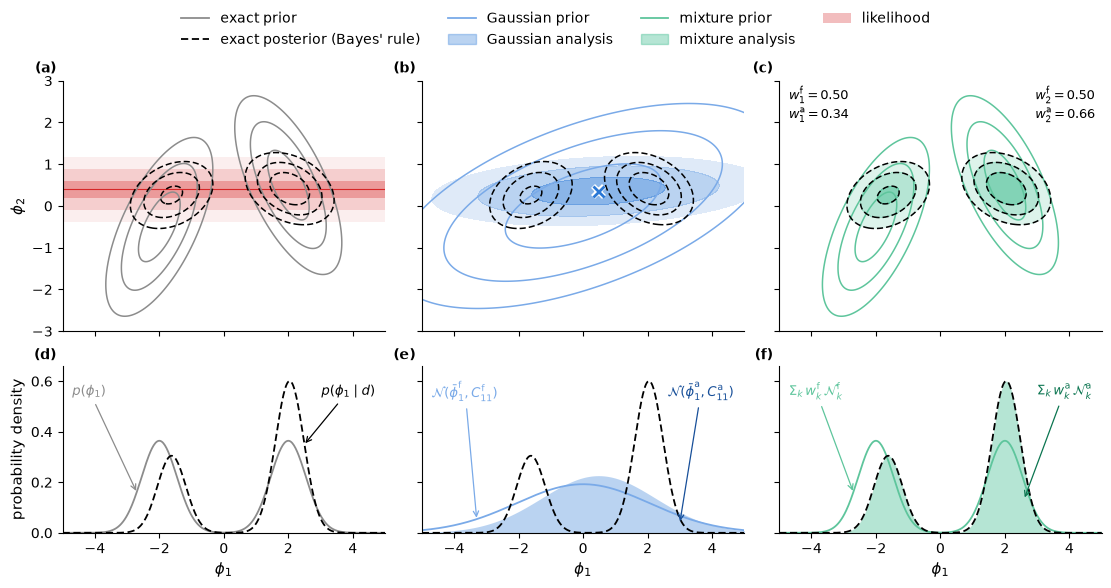

In [2]:
# Prior: two Gaussians of equal weight, apart in phi1, with correlations of opposite sign between phi1 and phi2
w_f = np.array([0.5, 0.5])
mu_f = np.array([[-2., -0.5], [2., 0.5]])
C_f = np.array([[[0.3, 0.25], [0.25, 0.5]],
                [[0.3, -0.25], [-0.25, 0.5]]])
M = np.array([[0., 1.]])                              # we observe phi2
d_2d, Cdd_2d = np.array([0.4]), np.eye(1) * 0.3 ** 2  # the data and their variance


def kalman(mu, C, d, Cdd):
    """Kalman analysis (2) of the Gaussian N(mu, C), and its evidence N(d; M mu, S)."""
    S = M @ C @ M.T + Cdd
    G = C @ M.T @ np.linalg.inv(S)
    return mu + G @ (d - M @ mu), C - G @ M @ C, multivariate_normal(M @ mu, S).pdf(d)


# Gaussian filter: the Kalman analysis of the Gaussian with the mean and the covariance of the prior
mu_g = w_f @ mu_f
C_g = np.einsum('k,kij->ij', w_f, C_f) + np.einsum('k,ki,kj->ij', w_f, mu_f - mu_g, mu_f - mu_g)
mu_ga, C_ga, _ = kalman(mu_g, C_g, d_2d, Cdd_2d)

# Mixture filter: the Kalman analysis of each Gaussian, and the weights times the evidence, Eq. (4)
mu_a, C_a, evidence = zip(*[kalman(mu, C, d_2d, Cdd_2d) for mu, C in zip(mu_f, C_f)])
w_a = w_f * np.array(evidence) / np.sum(w_f * np.array(evidence))

# Bayes' rule (1) on a grid: the prior times the likelihood, normalized
phi1, phi2 = np.linspace(-5, 5, 401), np.linspace(-3, 3, 301)
X = np.stack(np.meshgrid(phi1, phi2), axis=-1)
prior_2d = mixture_pdf(X, w_f, mu_f, C_f)
post_2d = prior_2d * np.exp(-0.5 * (X[..., 1] - d_2d[0]) ** 2 / Cdd_2d[0, 0])
post_2d /= post_2d.sum() * (phi1[1] - phi1[0]) * (phi2[1] - phi2[0])

print(f'weights of the Gaussians: forecast {w_f}, analysis {np.round(w_a, 2)}')
print(f'largest difference between the mixture analysis and Bayes\' rule: '
      f'{np.abs(mixture_pdf(X, w_a, mu_a, C_a) - post_2d).max() / post_2d.max():.0e} of the maximum density')
print(f'posterior density at the mean of the Gaussian analysis: '
      f'{mixture_pdf(mu_ga, w_a, mu_a, C_a) / post_2d.max():.0e} of the maximum density')
plot_bayes_2d(phi1, phi2, prior_2d, post_2d, d_2d, Cdd_2d, (mu_g, C_g), (mu_ga, C_ga), (w_f, mu_f, C_f),
              (w_a, mu_a, C_a))

The exact prior is grey, and the exact posterior is black and dashed. The light coloured lines are the priors of the two filters, and the coloured regions are their analyses. The lines and the regions enclose 50, 90 and 99% of the probability, the red bands enclose 50, 90 and 99% of the likelihood in $\phi_2$, and in the labels of (d-f), $\bar{\phi}_1$ and $C_{11}$ are the mean and the variance of $\phi_1$, and $\mathcal{N}_k^{\mathrm{f}}$ and $\mathcal{N}_k^{\mathrm{a}}$ are Gaussian $k$ before and after its analysis. Bayes' rule (a) multiplies the prior by the likelihood, which is a band around $\phi_2 = d$. The posterior keeps both modes: each mode moves along its own correlation, and the mode that predicts the data better gains weight (printed above). The Gaussian prior (b) covers both modes and the gap between them, and its correlation between $\phi_1$ and $\phi_2$ comes from the distance between the modes. The Gaussian analysis has its maximum in the gap (cross), where the posterior has almost no probability (printed above), and its density of $\phi_1$ (e) has one broad maximum, whereas the posterior has two. The mixture analysis (c, f) coincides with Bayes' rule to round-off.

Next, we draw $m = 20$ and $m = 200$ members from the prior and analyse them with the EnSRKF, with `mixture=1` and `mixture=2`. The model is the identity (`LinearModel`), because we need the analysis only, and the standard deviation of the prior plays the role of the climatology. Over $100$ ensembles, we score each analysis by the fraction of its members outside the region that holds 99% of the posterior probability, which is 1% for a sample of the posterior.

posterior probability of phi1 > 0: 0.66


m = 20: fraction of the members outside the region with 99% of the probability, over 100 ensembles: forecast 0.011, Gaussian analysis 0.202, mixture analysis 0.007; fraction of the mixture members with phi1 > 0: 0.68


m = 200: fraction of the members outside the region with 99% of the probability, over 100 ensembles: forecast 0.010, Gaussian analysis 0.186, mixture analysis 0.009; fraction of the mixture members with phi1 > 0: 0.66


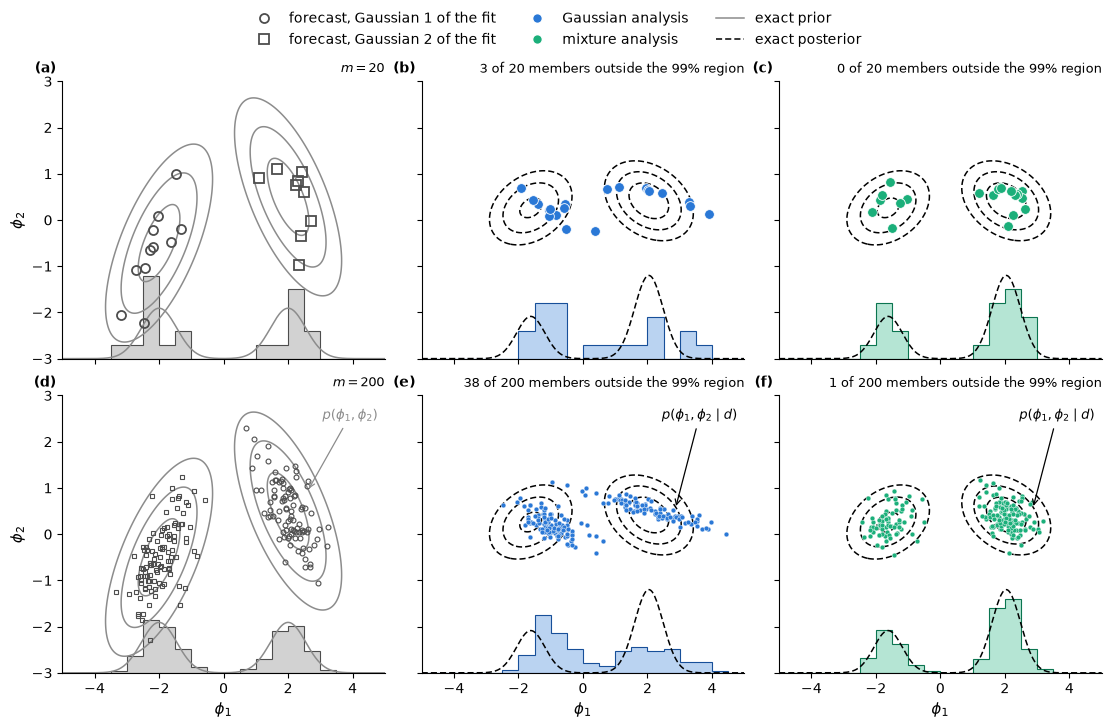

In [3]:
def sample_prior(rng, m):
    """`m` members drawn from the prior mixture, (2, m)."""
    k = rng.choice(len(w_f), m, p=w_f)
    return np.array([rng.multivariate_normal(mu_f[i], C_f[i]) for i in k]).T


def analyse_2d(Ef, mixture):
    """EnSRKF analysis of the members `Ef` (2, m) with the data `d_2d`, and the Gaussian of each member in the fit.
    The model is the identity, and the standard deviation of the prior plays the role of the climatology."""
    filt = EnSRKF(parent_model=LinearModel, F=np.eye(2), M_obs=M, m=Ef.shape[1], ensemble_psi0=Ef, inflation=1.0,
                  mixture=mixture, climatology=np.sqrt(np.diag(C_g)))
    Aa = filt.analysis_step(d_2d, Cdd_2d, return_analysis=True)
    labels = filt.mixture_history.labels
    return Aa, labels[0] if labels else np.zeros(Ef.shape[1], dtype=int)


level_f, level_a = hpd_level(prior_2d, 0.99), hpd_level(post_2d, 0.99)   # contours of the 99% regions


print(f'posterior probability of phi1 > 0: {w_a[mu_f[:, 0] > 0].sum():.2f}')
rng_2d, rows = np.random.default_rng(2), []
for m in (20, 200):
    scores = []
    for n in range(100):
        Ef = sample_prior(rng_2d, m)
        (Ag, _), (Am, labels) = analyse_2d(Ef, 1), analyse_2d(Ef, 2)
        if n == 0:                                                       # the ensemble shown
            analyses = {1: Ag, 2: Am}
            outside = {k: int(np.sum(mixture_pdf(A.T, w_a, mu_a, C_a) < level_a)) for k, A in analyses.items()}
            rows.append((Ef, labels, analyses, outside))
        scores.append([np.mean(mixture_pdf(Ef.T, w_f, mu_f, C_f) < level_f),
                       np.mean(mixture_pdf(Ag.T, w_a, mu_a, C_a) < level_a),
                       np.mean(mixture_pdf(Am.T, w_a, mu_a, C_a) < level_a), np.mean(Am[0] > 0)])
    print('m = {}: fraction of the members outside the region with 99% of the probability, over 100 ensembles: '
          'forecast {:.3f}, Gaussian analysis {:.3f}, mixture analysis {:.3f}; fraction of the mixture members with '
          'phi1 > 0: {:.2f}'.format(m, *np.mean(scores, axis=0)))
plot_members_2d(phi1, phi2, prior_2d, post_2d, rows)

The fit (a, d) assigns each forecast member to a Gaussian (circles and squares). The grey lines are the exact prior (a, d), and the black dashed lines are the exact posterior. Along the bottom of every panel, on one scale, the filled steps are the histograms of $\phi_1$ of the members, the grey curves are the exact $p(\phi_1)$ (a, d), and the dashed curves are the exact $p(\phi_1 \mid d)$ (b, c, e, f). The Gaussian analysis (b, e) moves every member with one gain, computed from the covariance of the whole ensemble, and places some members where the posterior has almost no probability (counted above the panels, and printed above over all the ensembles). The members keep part of the two modes, because the analysis is a linear transformation of the forecast members, but the histograms show the two groups displaced and spread with respect to the exact modes. The gain depends on the mean and the covariance of the members only, so the analysis ignores the two modes of the prior (a, d). Because the filter is Markovian, i.e., the next forecast starts from the analysis members alone, the shape that the analysis ignores is not recovered at later times: the members in the gap start the next forecast from the gap. Ten times more members (d-f) barely change the fraction of the Gaussian-analysis members outside the posterior (printed above): the error comes from the Gaussian assumption, not from sampling. The mixture analysis (c, f) moves each group within its own mode, and reallocates the members in proportion to the weights (4). Its histogram follows the exact posterior, and the fraction of members in each mode approximates the posterior probability of the mode (printed above), within the sampling error of the forecast. The rest of this tutorial analyses the Lorenz-63 system, in which the prior is not a Gaussian mixture and the model is nonlinear.

### 2) The mirror symmetry of the Lorenz-63 equations <a class="anchor" id="symmetry"></a>

We integrate a true trajectory, $\boldsymbol{\phi}^\dagger(t)$, and the trajectory that starts from its mirror image, $\mathcal{S}\boldsymbol{\phi}^\dagger(0)$.

largest |z - z_mirror| = 0.0e+00, largest |x + x_mirror| = 0.0e+00


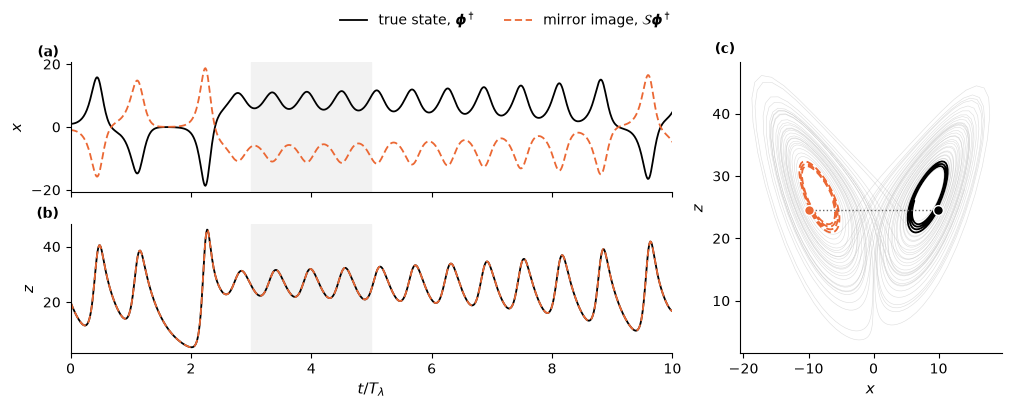

In [4]:
def trajectory(psi0, n_steps):
    model = Lorenz63(dt=dt, psi0=psi0)
    psi, t = model.time_integrate(n_steps)
    model.update_history(psi, t)
    return np.asarray(model.hist)[:, :3, 0], np.asarray(model.hist_t)


u_true, t_true = trajectory(np.array([1., 1., 20.]), int(40 * t_lyap / dt))
u_mirror, _ = trajectory(S * u_true[0], len(t_true) - 1)
print(f'largest |z - z_mirror| = {np.abs(u_true[:, 2] - u_mirror[:, 2]).max():.1e}, '
      f'largest |x + x_mirror| = {np.abs(u_true[:, 0] + u_mirror[:, 0]).max():.1e}')
plot_symmetry(t_true / t_lyap, u_true, u_mirror)

The two trajectories have opposite $x$ (a) and the same $z$ (b), to round-off. In the $x$-$z$ plane (c), over the shaded interval, the true trajectory turns around one lobe of the attractor and its mirror image around the other, at the same height $z$ (dotted). A record of $z$ is therefore consistent with both.

### 3) The posterior is bimodal <a class="anchor" id="posterior"></a>

We observe $z$ at the $N_\mathrm{obs}$ times $t_1, \dots, t_{N_\mathrm{obs}}$, with Gaussian noise of variance $C_{dd}$. By Bayes' rule, the posterior of the state at $t_{N_\mathrm{obs}}$ is

$$p(\boldsymbol{\phi} \mid z_{1:N_\mathrm{obs}}) \propto p(\boldsymbol{\phi}) \prod_{i=1}^{N_\mathrm{obs}} \exp\left(-\frac{\big(z_i - z(t_i)\big)^2}{2\,C_{dd}}\right),$$

where $z_i$ is the observation at $t_i$; $z(t_i)$ is the $z$ component, at $t_i$, of the trajectory through $\boldsymbol{\phi}$; and the prior, $p(\boldsymbol{\phi})$, is the climatology, i.e., the distribution of the states on the attractor. We approximate the posterior by importance sampling: we draw states from the attractor, integrate them through the observation times, and weight each state by the likelihood of the data. Because the attractor is symmetric, we add the mirror image of every state.

In [5]:
rng = np.random.default_rng(0)
prior = sample_attractor(rng)                    # states on the attractor and their mirror images
climatology = prior.std(axis=1)
print(f'{prior.shape[1]} samples; climatological standard deviation of x, y, z: {np.round(climatology, 1)}')

1600000 samples; climatological standard deviation of x, y, z: [7.9 9.  8.6]


given z_5 alone: effective sample size 71784, probability of x > 0 0.50
given z_1, ..., z_5: effective sample size 98, probability of x > 0 0.50


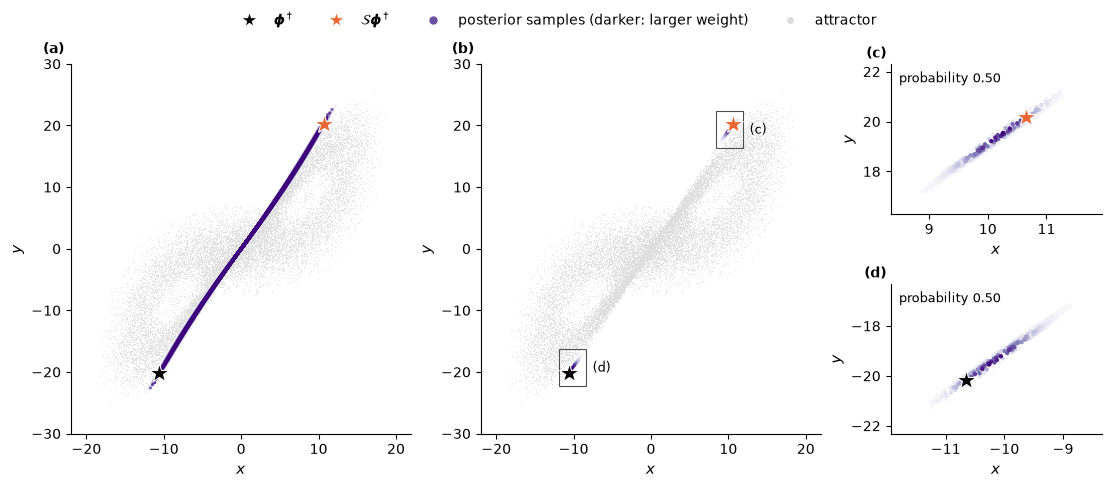

In [6]:
std_d, N_obs, Nt_obs = 0.5, 5, 10   # noise of the data, number of observations, RK4 steps between observations

# A true state whose x is far from zero at the last two observations, so that the two modes are apart
u_t = rk4(np.array([1., 1., 20.]), 4000)
while not (abs(rk4(u_t, (N_obs - 1) * Nt_obs)[0]) > 7 and abs(rk4(u_t, (N_obs - 2) * Nt_obs)[0]) > 6):
    u_t = rk4(u_t, 5)

samples, log_w, d, posterior = prior.copy(), np.zeros(prior.shape[1]), [], {}
for i in range(N_obs):
    if i > 0:                                                    # forecast to the next observation
        samples, u_t = rk4(samples, Nt_obs), rk4(u_t, Nt_obs)
    if i == N_obs - 1:
        posterior['forecast'] = samples.copy(), log_w.copy()     # given z_1, ..., z_{N_obs - 1}
    d.append(u_t[2] + std_d * rng.standard_normal())             # observation of z
    log_w = log_w - 0.5 * ((samples[2] - d[-1]) / std_d) ** 2    # times its likelihood
posterior['all'] = samples, log_w
posterior['last'] = samples, -0.5 * ((samples[2] - d[-1]) / std_d) ** 2
u_true_last = u_t

for key, given in (('last', f'z_{N_obs} alone'), ('all', f'z_1, ..., z_{N_obs}')):
    w = weights(posterior[key][1])
    print(f'given {given}: effective sample size {1 / np.sum(w ** 2):.0f}, '
          f'probability of x > 0 {w[posterior[key][0][0] > 0].sum():.2f}')
plot_posterior(posterior['last'], posterior['all'], u_true_last, prior[:, ::80])

Given the last observation alone (a), the states lie on a curve that crosses both lobes and is symmetric under $\mathcal{S}$. Given all the observations (b), the posterior concentrates in two modes, near the mirror image (c) and near the true state (d), with equal probability (printed above). More observations of $z$ narrow the modes, but do not remove either.

### 4) One analysis of a bimodal forecast <a class="anchor" id="analysis"></a>

We draw $m = 20$ members from the forecast at $t_{N_\mathrm{obs}}$, i.e., the posterior given $z_1, \dots, z_{N_\mathrm{obs} - 1}$, propagated to $t_{N_\mathrm{obs}}$, which has two modes. We assimilate $z_{N_\mathrm{obs}}$ with the Gaussian EnSRKF (`mixture=1`, the default) and with the Gaussian-mixture EnSRKF (`mixture=2`), without inflation. We score each analysis by the median distance of the members to the mode on their side of $x = 0$, over $50$ forecast ensembles.

median distance to the modes over the 50 ensembles: forecast 1.71, Gaussian 1.45, mixture 0.54
the mixture analysis is the closer in 50 of the 50 ensembles
covariance of x and z in this ensemble -8.83, within x > 0 0.63, within x < 0 -0.68


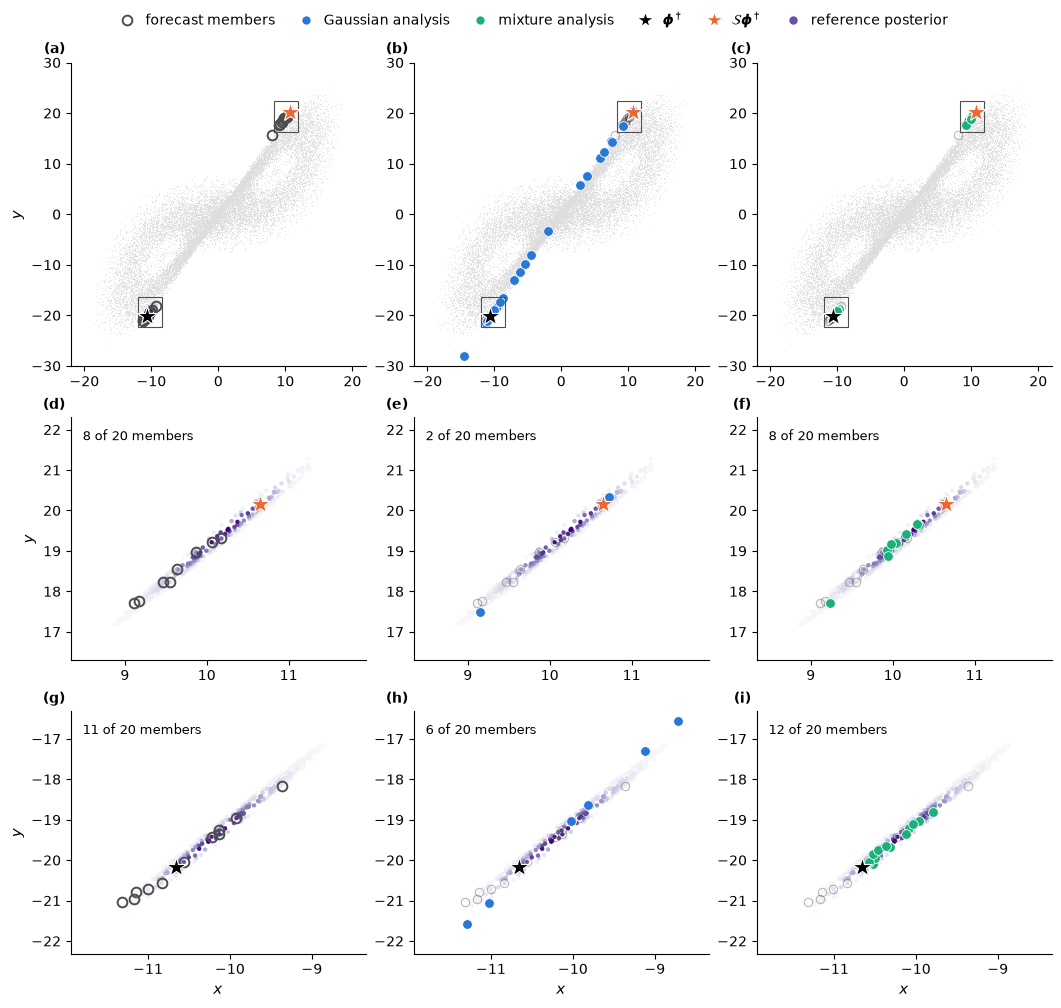

In [7]:
m, Cdd = 20, np.eye(1) * std_d ** 2


def analyse(Ef, mixture):
    filt = EnSRKF(parent_model=Lorenz63, dt=dt, m=m, ensemble_psi0=Ef, observe_dims=[2], inflation=1.0,
                  mixture=mixture, climatology=climatology)
    return filt.analysis_step(np.array([d[-1]]), Cdd, return_analysis=True)


modes = mode_means(*posterior['all'])
rng_f = np.random.default_rng(1)
samples_f, w_f = posterior['forecast'][0], weights(posterior['forecast'][1])
forecasts = [samples_f[:, rng_f.choice(samples_f.shape[1], m, p=w_f)] for _ in range(50)]
dist = np.array([[distance_to_modes(E, modes) for E in (Ef, analyse(Ef, 1), analyse(Ef, 2))] for Ef in forecasts])
print('median distance to the modes over the 50 ensembles: forecast {:.2f}, Gaussian {:.2f}, mixture {:.2f}'.format(
    *np.median(dist, axis=0)))
print(f'the mixture analysis is the closer in {np.sum(dist[:, 2] < dist[:, 1])} of the 50 ensembles')

Ef = forecasts[0]                                                # the ensemble shown
print('covariance of x and z in this ensemble {:.2f}, within x > 0 {:.2f}, within x < 0 {:.2f}'.format(
    np.cov(Ef)[0, 2], np.cov(Ef[:, Ef[0] > 0])[0, 2], np.cov(Ef[:, Ef[0] < 0])[0, 2]))
plot_analysis(Ef, {k: analyse(Ef, k) for k in (1, 2)}, posterior['all'], u_true_last, prior[:, ::80])

The top row (a-c) shows the attractor, with boxes around the two modes, and the lower rows (d-i) zoom on the modes. Within each mode, $x$ and $z$ have their own correlation, whereas the covariance of the whole ensemble adds the distance between the modes (printed above). The Gaussian analysis (b, e, h) corrects the members with this covariance, which belongs to neither mode, and moves them along the line between the modes, where the posterior has negligible probability. The mixture analysis (c, f, i) corrects each mode with its own covariance, and keeps the members near the modes.

### 5) Twin experiment <a class="anchor" id="twin"></a>

We now cycle the two filters. The true state is the trajectory of Section 2, and the data are $z$ every three time steps, with the noise of Section 3, from $2$ to $22$ Lyapunov times. Both filters start from the same $m$ members, drawn from the attractor, i.e., from both lobes, and inflate the analysis by a constant factor; the mixture inflates each Gaussian about its own mean.

Gaussian EnSRKF: error of the mean on z over the last 5 Lyapunov times of the data 0.03
Gaussian-mixture EnSRKF: error of the mean on z over the last 5 Lyapunov times of the data 0.03


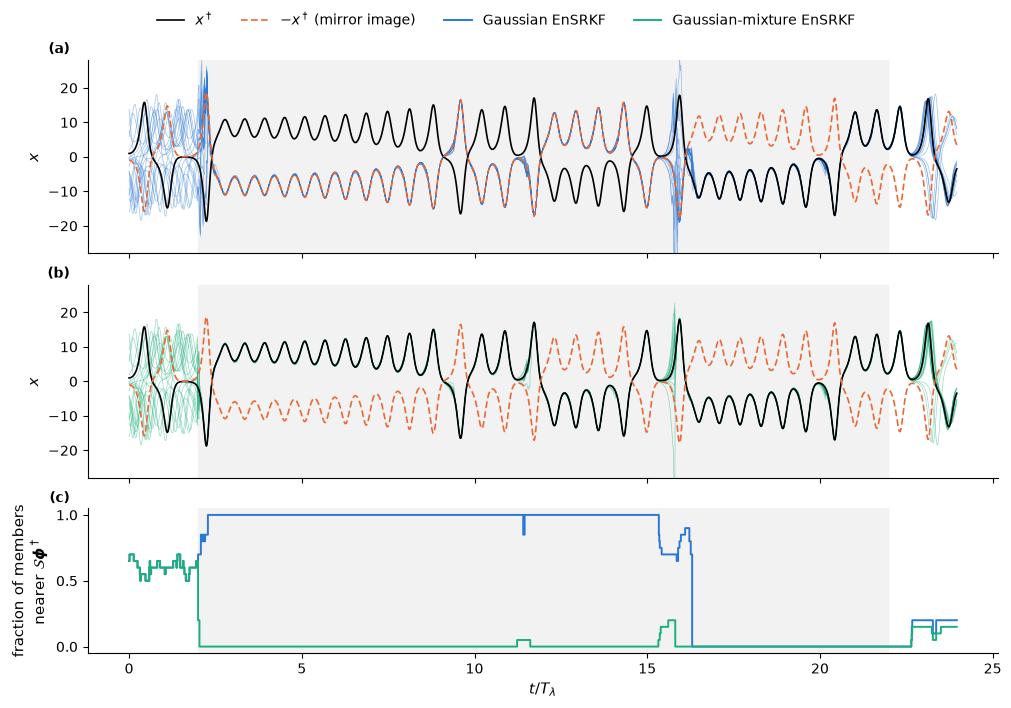

In [8]:
i_obs = np.arange(int(round(2 * t_lyap / dt)), int(round(22 * t_lyap / dt)), 3)    # time steps of the data
t_last = t_true[i_obs[-1]]


def twin(mixture, seed):
    rng = np.random.default_rng(seed)
    d = u_true[i_obs, 2] + std_d * rng.standard_normal(len(i_obs))
    E0 = prior[:, rng.choice(prior.shape[1], m, replace=False)]
    filt = EnSRKF(parent_model=Lorenz63, dt=dt, m=m, ensemble_psi0=E0, observe_dims=[2], inflation=1.05,
                  mixture=mixture, climatology=climatology)
    for k, i in enumerate(i_obs):
        filt.forecast_step(t_end=t_true[i])
        filt.analysis_step(d=d[k:k + 1], Cdd=Cdd)
    filt.forecast_step(t_end=t_last + 2 * t_lyap)                # forecast without data
    scores = twin_scores(filt, t_true, u_true, t_last, window=5 * t_lyap, scale=climatology[2])
    filt.model.close()
    return scores


runs = {mixture: twin(mixture, seed=0) for mixture in (1, 2)}
for mixture in (1, 2):
    print(f'{NAME[mixture]}: error of the mean on z over the last 5 Lyapunov times of the data {runs[mixture]["e_z"]:.2f}')
plot_twin(runs, (t_true[i_obs[0]], t_last), t_lyap)

Both filters follow $z$ (printed above), and, within a few analyses, each ensemble gathers on one branch (c). The Gaussian ensemble cannot represent two modes. The mixture ensemble starts with a Gaussian on each branch, but while the members synchronize, the probability of the data differs between the two Gaussians, and one Gaussian receives all the members. A branch that loses its members does not recover. Over ten runs with different noise and initial members, we count the runs that keep members on both branches at the last observation.

In [9]:
print(f"{'filter':<26}{'z synchronized':>16}{'both branches at the last observation':>40}")
for mixture in (1, 2):
    res = [twin(mixture, seed) for seed in range(10)]
    print(f'{NAME[mixture]:<26}{sum(r["e_z"] < 0.3 for r in res):>13}/10'
          f'{sum(0 < r["mirror_last"] < 1 for r in res):>37}/10')

filter                      z synchronized   both branches at the last observation


Gaussian EnSRKF                      10/10                                    0/10


Gaussian-mixture EnSRKF              10/10                                    3/10


## Summary <a class="anchor" id="summary"></a>

- The mirror symmetry of the Lorenz-63 equations leaves two modes of equal probability in $p(x, y \mid z)$.
- In Bayesian terms, the Gaussian filter computes the posterior of the Gaussian with the mean and the covariance of the prior. With a Gaussian-mixture prior and a linear measurement operator, Bayes' rule gives a Gaussian-mixture posterior: one Kalman analysis per Gaussian, and the weight of each Gaussian times its evidence.
- One Gaussian analysis of a forecast with two modes corrects the members with a covariance that belongs to neither mode, and moves them between the modes.
- The Gaussian-mixture ensemble filter (`mixture=2`) analyses each mode with its own mean and covariance, and weights the modes by the probability of the data. Cycled, it keeps both modes only while each mode has enough members.
- With the true model, a state between the modes is a valid initial condition. With a model learned from data, such as an echo state network, a state between the modes may lie off the learned attractor, from which the forecast diverges. The mixture analysis does not create such states.

___

### Exercises

<em><font color="#7CB9E8">  - In Section 1, move the data, $d$, from one mode to the other. How do the weights change, and where is the maximum of the Gaussian analysis?</font></em>

<em><font color="#7CB9E8">  - How do the results change if we observe $x$ instead of $z$? (Hint: the symmetry changes the sign of $x$.)</font></em>

<em><font color="#7CB9E8">  - How does the twin experiment change with $m = 10$ members, i.e., five per mode?</font></em>

___